==========================================
ANALISIS EXPLORATORIO DE DATOS CON PANDAS
Dataset: songs_2000_2020_50k.csv
==========================================
Autoras: 

Sara Margarita Gonzalez Burgos

Eimmy Edith Ramirez Fernandez

Materia: Analítica de Datos

Objetivo:
Aplicar técnicas de análisis, limpieza,
transformación y exploración de datos.

## Importacion de librerias

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

## Carga del data set 

In [2]:
df = pd.read_csv("songs_2000_2020_50k.csv")

print("Dataset cargado correctamente")

Dataset cargado correctamente


## Exploracion inicial

In [3]:
df.select_dtypes(exclude="number").describe()

,Title,Artist,Album,Genre,Release Date
count,50000,50000,50000,50000,50000
unique,46516,40156,25959,10,7655
top,Husband.,James Smith,When.,Country,2019-03-30
freq,12,23,43,5176,18


In [4]:
df.nunique()

Title           46516
Artist          40156
Album           25959
Genre              10
Release Date     7655
Duration          181
Popularity        101
dtype: int64

In [5]:
df.head()

,Title,Artist,Album,Genre,Release Date,Duration,Popularity
0,Include name this.,Patrick Anderson,Care.,R&B,2008-01-09,262,71
1,Manage west energy.,Eric Miller,Raise get.,Jazz,2011-08-20,187,37
2,Evening court painting.,Richard Curry,Sport.,Electronic,2010-05-30,212,58
3,Section turn hour.,James Smith,Full.,Hip-Hop,2014-10-12,272,59
4,Five agreement teach.,Amy Rodriguez,Eat.,Blues,2005-06-09,131,34


In [6]:
df.tail()

,Title,Artist,Album,Genre,Release Date,Duration,Popularity
49995,Thing.,Brandon Thomas,Lawyer sign.,Rock,2008-06-07,300,95
49996,Option.,Barry White,Cold.,Pop,2016-09-06,220,23
49997,Ability ever.,Leah Obrien,Trade.,Blues,2013-10-16,257,79
49998,Occur claim who.,Ashley James,Explain moment.,Jazz,2018-03-06,262,22
49999,Value.,John Wong,Each.,Country,2002-11-26,203,70


In [7]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 50000
Columnas: 7


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Title         50000 non-null  str  
 1   Artist        50000 non-null  str  
 2   Album         50000 non-null  str  
 3   Genre         50000 non-null  str  
 4   Release Date  50000 non-null  str  
 5   Duration      50000 non-null  int64
 6   Popularity    50000 non-null  int64
dtypes: int64(2), str(5)
memory usage: 5.3 MB


In [9]:
df.dtypes

Title             str
Artist            str
Album             str
Genre             str
Release Date      str
Duration        int64
Popularity      int64
dtype: object

In [10]:
df.describe()

,Duration,Popularity
count,50000.000000,50000.000000
mean,209.742900,50.263840
std,52.492824,29.142209
min,120.000000,0.000000
25%,164.000000,25.000000
50%,210.000000,50.000000
75%,255.000000,76.000000
max,300.000000,100.000000


## Limpieza de datos

In [11]:
print("Popularidad fuera de 0-100:", ((df["Popularity"] < 0) | (df["Popularity"] > 100)).sum())
print("Duración fuera de 120-300 s:", ((df["Duration"] < 120) | (df["Duration"] > 300)).sum())

Popularidad fuera de 0-100: 0
Duración fuera de 120-300 s: 0


In [12]:
df.isnull().sum()

Title           0
Artist          0
Album           0
Genre           0
Release Date    0
Duration        0
Popularity      0
dtype: int64

In [13]:
(df.isnull().sum() / len(df)) * 100

Title           0.0
Artist          0.0
Album           0.0
Genre           0.0
Release Date    0.0
Duration        0.0
Popularity      0.0
dtype: float64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop_duplicates()

print("Duplicados eliminados")

Duplicados eliminados


In [16]:
columnas_numericas = df.select_dtypes(include=np.number).columns

columnas_numericas

Index(['Duration', 'Popularity'], dtype='str')

In [17]:
if df[columnas_numericas].isnull().sum().sum() > 0:
    df[columnas_numericas] = df[columnas_numericas].fillna(df[columnas_numericas].mean())
else:
    print("No hay valores numéricos nulos, no se requiere imputación")

No hay valores numéricos nulos, no se requiere imputación


In [18]:
columnas_categoricas = df.select_dtypes(exclude="number").columns
columnas_categoricas

Index(['Title', 'Artist', 'Album', 'Genre', 'Release Date'], dtype='str')

In [19]:
print(df[columnas_categoricas].isnull().sum())
print("No hay nulos categóricos, no se requiere imputación")

Title           0
Artist          0
Album           0
Genre           0
Release Date    0
dtype: int64
No hay nulos categóricos, no se requiere imputación


In [20]:
df["Artist"].value_counts().head(10)

Artist
James Smith         23
Michael Johnson     21
Robert Johnson      20
Jessica Smith       19
Jennifer Johnson    18
David Williams      16
Michael Smith       16
David Smith         16
James Brown         16
Nicole Smith        15
Name: count, dtype: int64

## Transformacion de variables

In [21]:
df["Grupo_Duracion"] = pd.cut(
    df["Duration"],
    bins=[119, 164, 209, 254, 300],
    labels=["2:00 - 2:44", "2:45 - 3:29", "3:30 - 4:14", "4:15 - 5:00"]
)

df[["Duration", "Grupo_Duracion"]].head()

,Duration,Grupo_Duracion
0,262,4:15 - 5:00
1,187,2:45 - 3:29
2,212,3:30 - 4:14
3,272,4:15 - 5:00
4,131,2:00 - 2:44


In [22]:
df["Grupo_Popularidad"] = pd.cut(
    df["Popularity"],
    bins=[0, 25, 50, 75, 100],
    labels=["Baja", "Media", "Alta", "Muy Alta"],
    include_lowest=True
)

print("Nulos en Grupo_Popularidad:", df["Grupo_Popularidad"].isna().sum())
df[["Popularity", "Grupo_Popularidad"]].head()

Nulos en Grupo_Popularidad: 0


,Popularity,Grupo_Popularidad
0,71,Alta
1,37,Media
2,58,Alta
3,59,Alta
4,34,Media


In [23]:
df["Grupo_Duracion"].value_counts().sort_index()

Grupo_Duracion
2:00 - 2:44    12651
2:45 - 3:29    12297
3:30 - 4:14    12364
4:15 - 5:00    12688
Name: count, dtype: int64

In [24]:
df["Release Date"] = pd.to_datetime(df["Release Date"])
df["Year"] = df["Release Date"].dt.year

In [25]:
df["Grupo_Popularidad"].value_counts()

Grupo_Popularidad
Baja        12655
Muy Alta    12504
Alta        12475
Media       12366
Name: count, dtype: int64

## Deteccion de outliers

In [26]:
df["Popularity"].mean()

np.float64(50.26384)

In [27]:
df["Duration"].mean()

np.float64(209.7429)

In [28]:
Q1, Q3 = df["Duration"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_dur = df[(df["Duration"] < lim_inf) | (df["Duration"] > lim_sup)]
print("Límites:", lim_inf, lim_sup, "| Outliers en Duration:", len(outliers_dur))

Límites: 27.5 391.5 | Outliers en Duration: 0


In [29]:
df.groupby("Duration")["Popularity"].mean()

Duration
120    49.946154
121    47.977528
122    46.955556
123    50.525926
124    50.436214
         ...    
296    48.969283
297    49.870229
298    49.105455
299    46.233227
300    51.121212
Name: Popularity, Length: 181, dtype: float64

In [30]:
df.groupby("Genre")["Popularity"].mean()

Genre
Blues         49.519506
Classical     50.686042
Country       50.264297
Electronic    49.794686
Hip-Hop       49.967018
Jazz          50.630694
Pop           50.397732
R&B           50.426302
Reggae        50.862920
Rock          50.112618
Name: Popularity, dtype: float64

In [31]:
df.groupby("Grupo_Duracion")["Popularity"].mean()

Grupo_Duracion
2:00 - 2:44    49.972650
2:45 - 3:29    50.258681
3:30 - 4:14    50.458913
4:15 - 5:00    50.369089
Name: Popularity, dtype: float64

In [32]:
Q1 = df["Popularity"].quantile(0.25)
Q3 = df["Popularity"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Límite inferior: -51.5
Límite superior: 152.5


In [33]:
outliers = df[
    (df["Popularity"] < limite_inferior) |
    (df["Popularity"] > limite_superior)
]

outliers

,Title,Artist,Album,Genre,Release Date,Duration,Popularity,Grupo_Duracion,Grupo_Popularidad,Year


In [34]:
print("Outliers encontrados:", len(outliers))

Outliers encontrados: 0


## Exportacion del data set limpio

In [35]:
df.to_csv(
    "songs_2000_2020_50k_limpio.csv",
    index=False
)

print("Archivo exportado correctamente")

Archivo exportado correctamente


In [36]:
print("""
CONCLUSIONES

1. Se limpió y validó el dataset de 50,000 canciones: sin nulos, sin duplicados y con valores dentro de rango.
2. Se crearon las variables Grupo_Duracion, Grupo_Popularidad y Year para el análisis.
3. No se detectaron outliers por el método IQR en Popularidad ni en Duración.
4. La popularidad promedio es similar en todos los géneros (49.5 a 50.9) y en todos los grupos de duración.
5. No existe correlación relevante entre duración, año y popularidad.
6. Los datos tienen distribución casi uniforme, lo que sugiere un dataset sintético.
7. Se generó un dataset limpio que alimenta el dashboard interactivo (app.py).
""")


CONCLUSIONES

1. Se limpió y validó el dataset de 50,000 canciones: sin nulos, sin duplicados y con valores dentro de rango.
2. Se crearon las variables Grupo_Duracion, Grupo_Popularidad y Year para el análisis.
3. No se detectaron outliers por el método IQR en Popularidad ni en Duración.
4. La popularidad promedio es similar en todos los géneros (49.5 a 50.9) y en todos los grupos de duración.
5. No existe correlación relevante entre duración, año y popularidad.
6. Los datos tienen distribución casi uniforme, lo que sugiere un dataset sintético.
7. Se generó un dataset limpio que alimenta el dashboard interactivo (app.py).



## Visualizacion

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

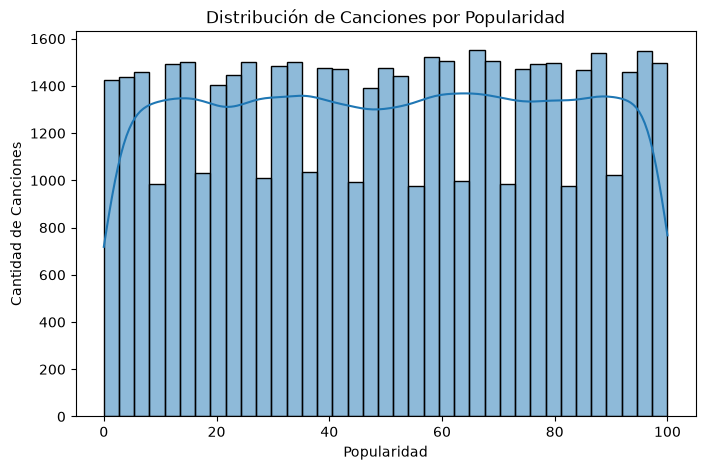

In [38]:
plt.figure(figsize=(8,5))
sns.histplot(df["Popularity"], kde=True)
plt.title("Distribución de Canciones por Popularidad")
plt.xlabel("Popularidad")
plt.ylabel("Cantidad de Canciones")
plt.show()

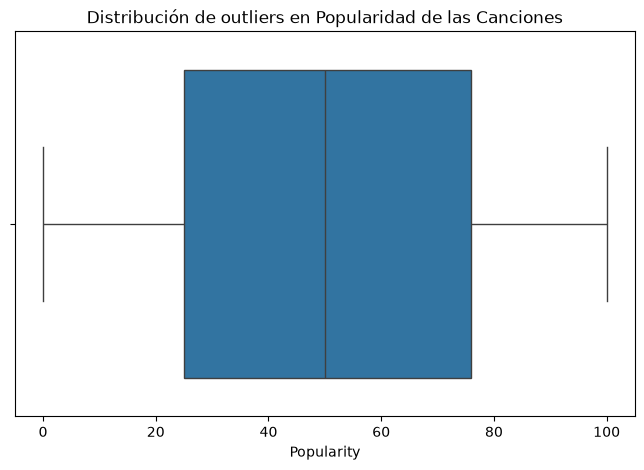

In [39]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Popularity"])
plt.title("Distribución de outliers en Popularidad de las Canciones")
plt.show()

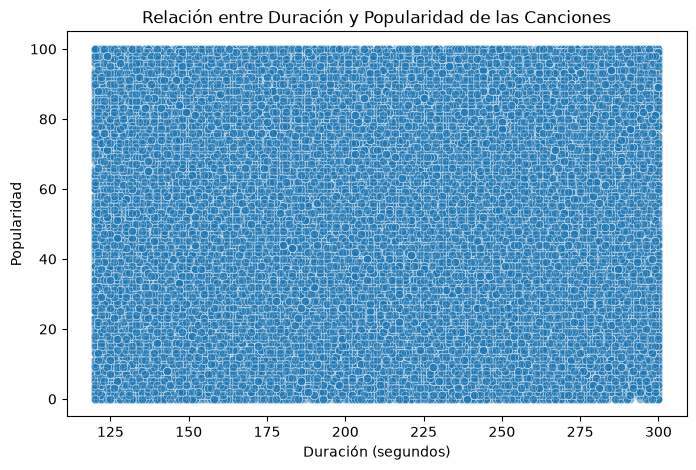

In [40]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="Duration",
    y="Popularity",
    data=df,
    alpha=0.5
)

plt.title("Relación entre Duración y Popularidad de las Canciones")
plt.xlabel("Duración (segundos)")
plt.ylabel("Popularidad")

plt.show()

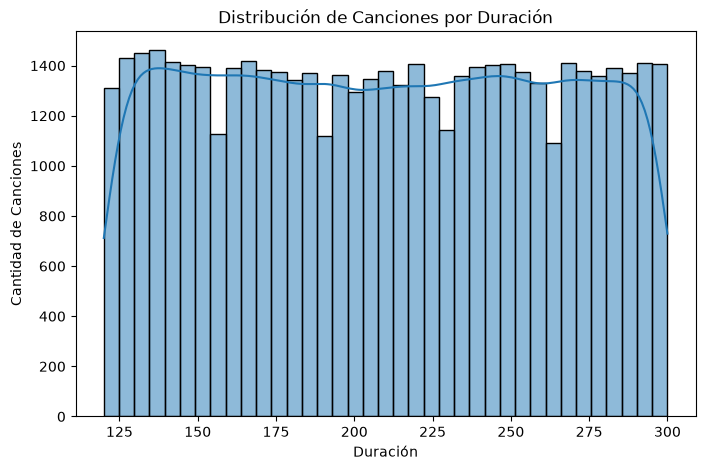

In [41]:
plt.figure(figsize=(8,5))
sns.histplot(df["Duration"], kde=True)
plt.title("Distribución de Canciones por Duración")
plt.xlabel("Duración")
plt.ylabel("Cantidad de Canciones")
plt.show()

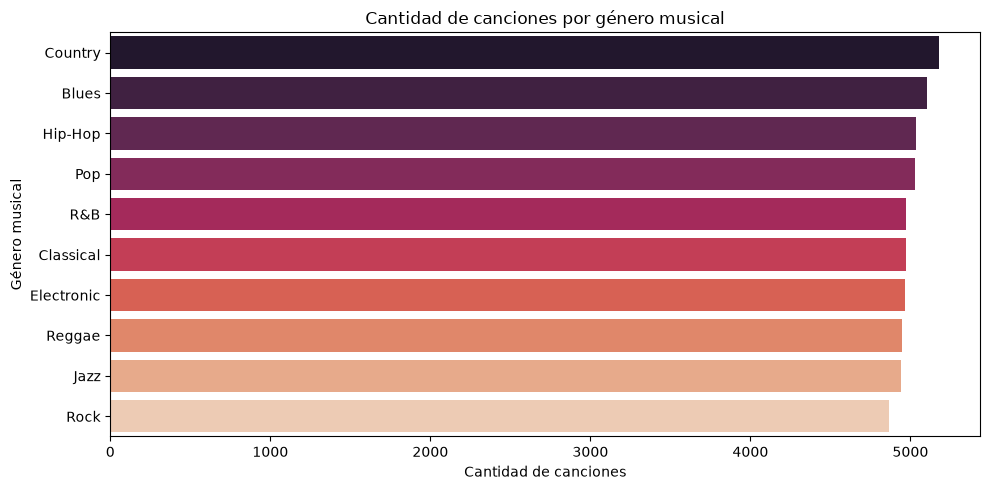

In [42]:
conteo_genero = df["Genre"].value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=conteo_genero.values, y=conteo_genero.index,
            hue=conteo_genero.index, legend=False, palette="rocket")
plt.title("Cantidad de canciones por género musical")
plt.xlabel("Cantidad de canciones")
plt.ylabel("Género musical")
plt.tight_layout()
plt.show()

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

plt.style.use('ggplot')

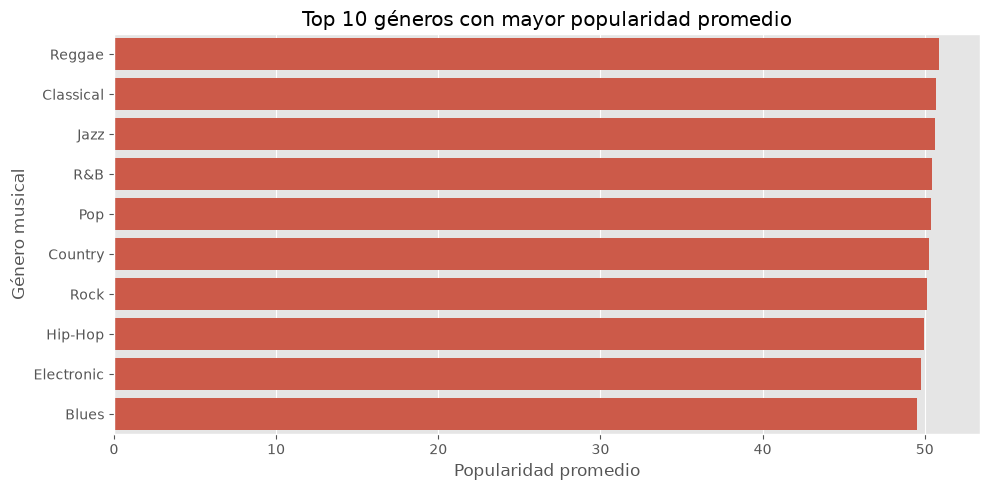

In [44]:
popularidad_genero = (
    df.groupby("Genre")["Popularity"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(x=popularidad_genero.values, y=popularidad_genero.index)
plt.title("Top 10 géneros con mayor popularidad promedio")
plt.xlabel("Popularidad promedio")
plt.ylabel("Género musical")
plt.tight_layout()
plt.show()

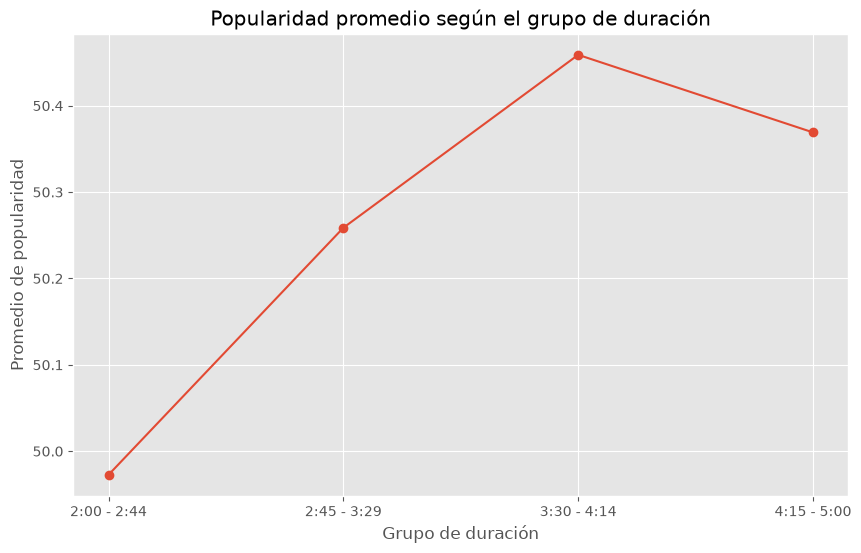

In [45]:
promedio_duracion = df.groupby("Grupo_Duracion", observed=False)["Popularity"].mean()

plt.figure(figsize=(10,6))
plt.plot(
    promedio_duracion.index.astype(str),
    promedio_duracion.values,
    marker='o',
    linestyle='-'
)

plt.title("Popularidad promedio según el grupo de duración")
plt.xlabel("Grupo de duración")
plt.ylabel("Promedio de popularidad")
plt.show()

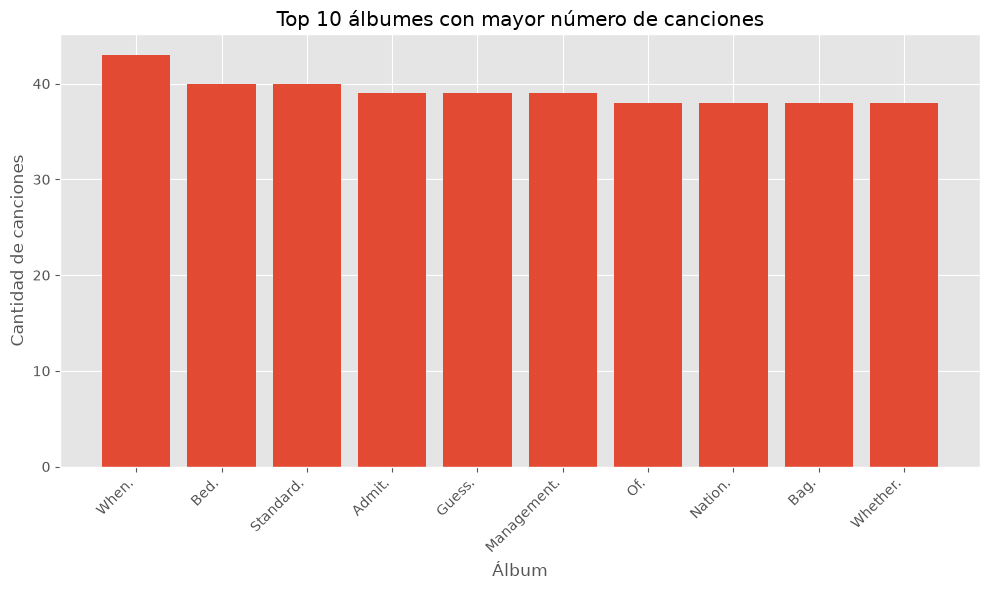

In [46]:
album_counts = df["Album"].value_counts().head(10)

plt.figure(figsize=(10,6))
plt.bar(album_counts.index.astype(str), album_counts.values)
plt.title("Top 10 álbumes con mayor número de canciones")
plt.xlabel("Álbum")
plt.ylabel("Cantidad de canciones")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

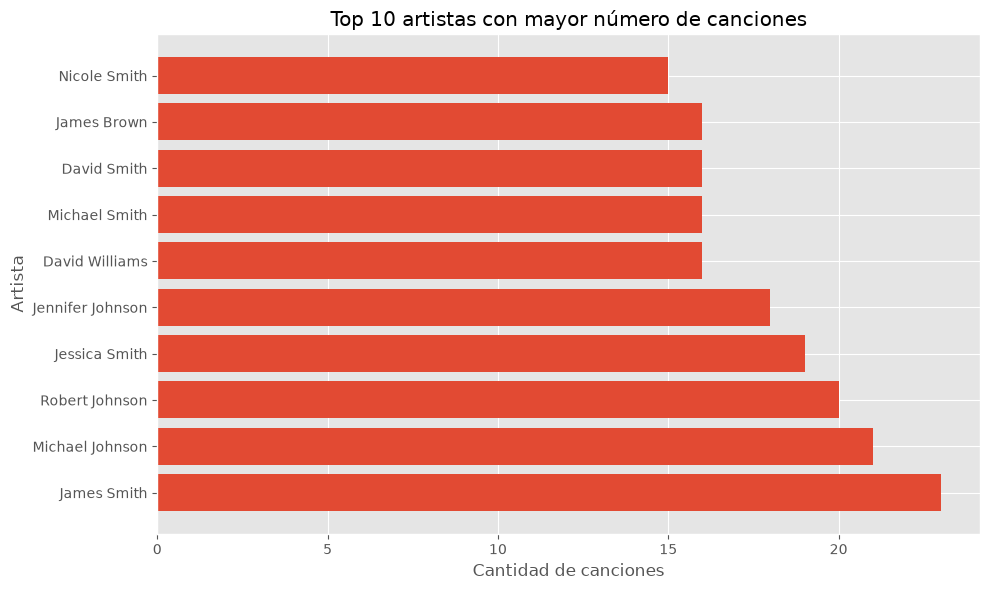

In [47]:
artist_counts = df["Artist"].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(artist_counts.index.astype(str), artist_counts.values)
plt.title("Top 10 artistas con mayor número de canciones")
plt.xlabel("Cantidad de canciones")
plt.ylabel("Artista")
plt.tight_layout()
plt.show()

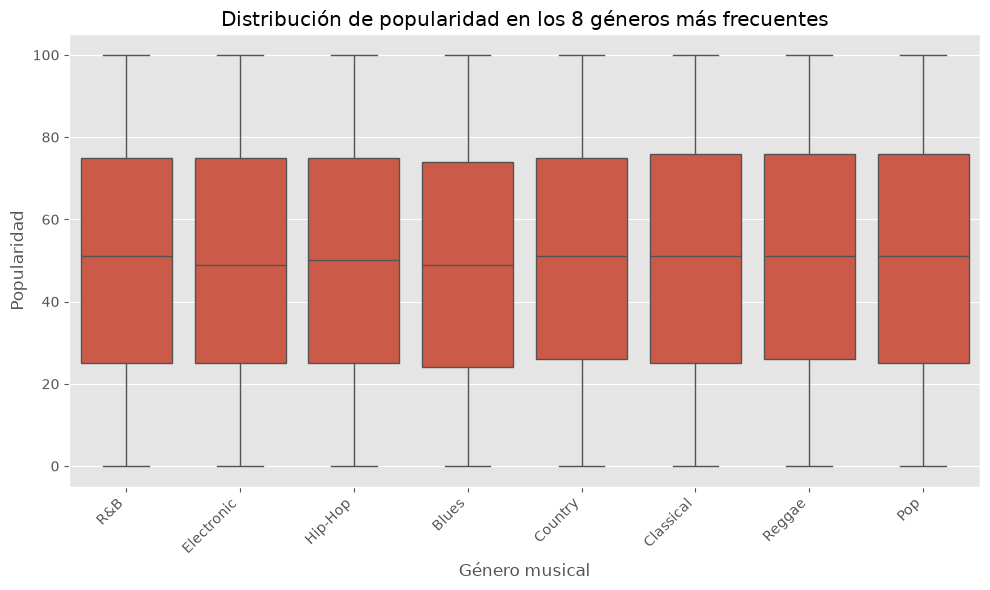

In [48]:
generos_principales = df["Genre"].value_counts().head(8).index
datos_generos = df[df["Genre"].isin(generos_principales)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=datos_generos, x="Genre", y="Popularity")
plt.title("Distribución de popularidad en los 8 géneros más frecuentes")
plt.xlabel("Género musical")
plt.ylabel("Popularidad")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

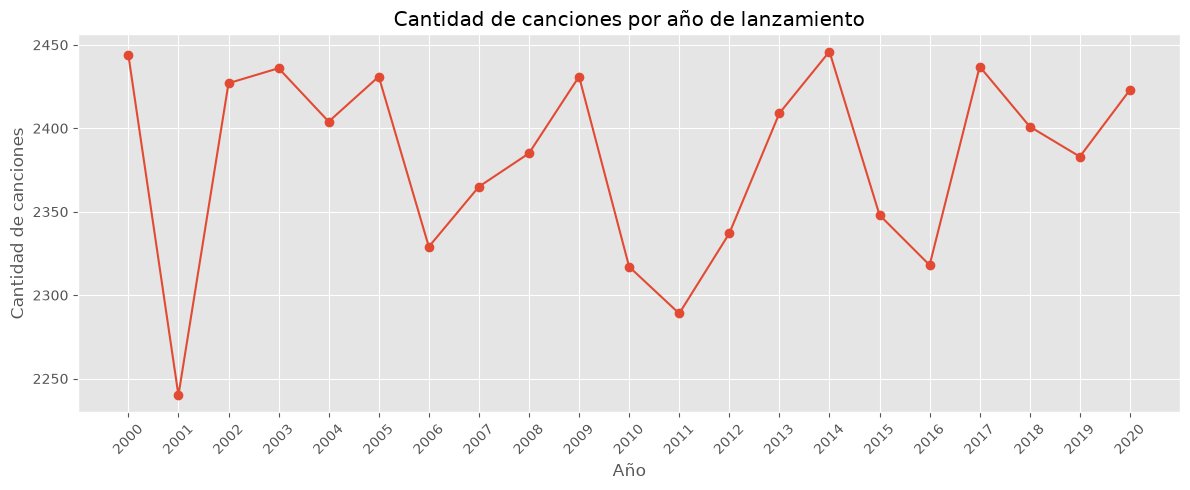

In [49]:
canciones_año = df["Year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(canciones_año.index, canciones_año.values, marker="o")
plt.title("Cantidad de canciones por año de lanzamiento")
plt.xlabel("Año")
plt.ylabel("Cantidad de canciones")
plt.xticks(canciones_año.index, rotation=45)
plt.tight_layout()
plt.show()

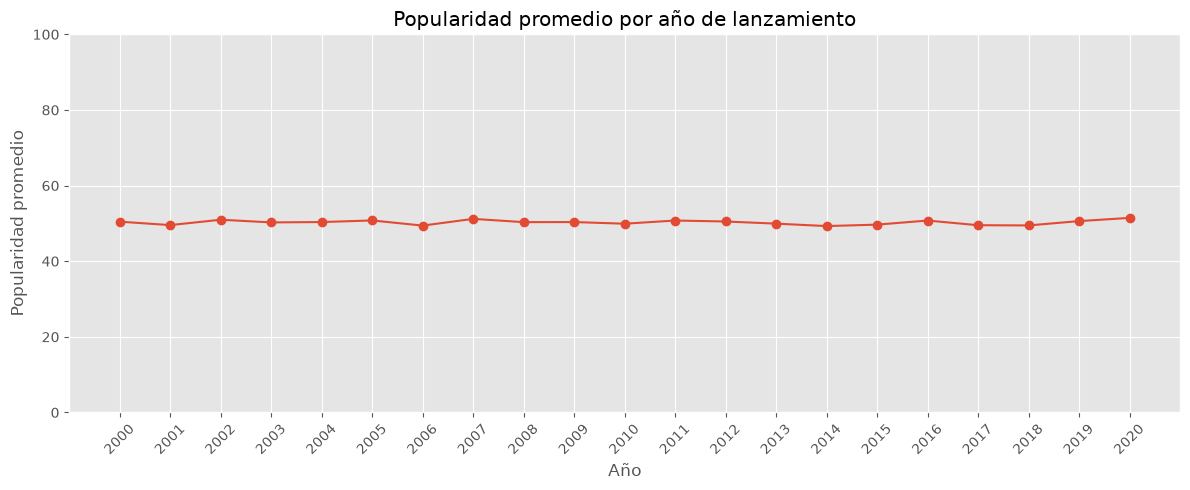

In [50]:
pop_año = df.groupby("Year")["Popularity"].mean()

plt.figure(figsize=(12, 5))
plt.plot(pop_año.index, pop_año.values, marker="o")
plt.ylim(0, 100)
plt.title("Popularidad promedio por año de lanzamiento")
plt.xlabel("Año")
plt.ylabel("Popularidad promedio")
plt.xticks(pop_año.index, rotation=45)
plt.tight_layout()
plt.show()

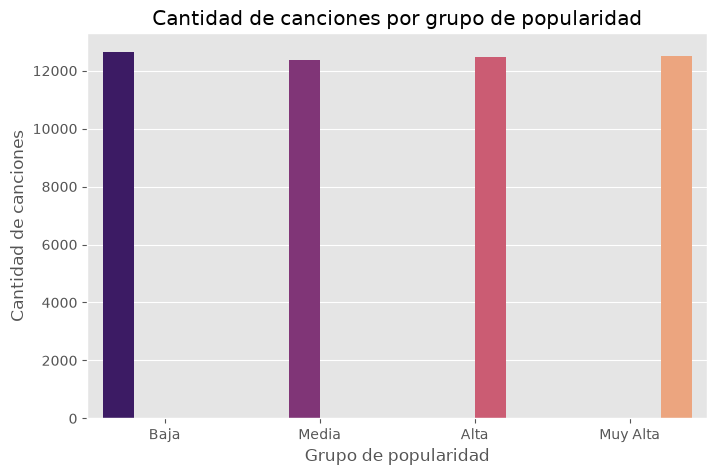

In [51]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Grupo_Popularidad", hue="Grupo_Popularidad", legend=False,
              order=["Baja", "Media", "Alta", "Muy Alta"], palette="magma")
plt.title("Cantidad de canciones por grupo de popularidad")
plt.xlabel("Grupo de popularidad")
plt.ylabel("Cantidad de canciones")
plt.show()

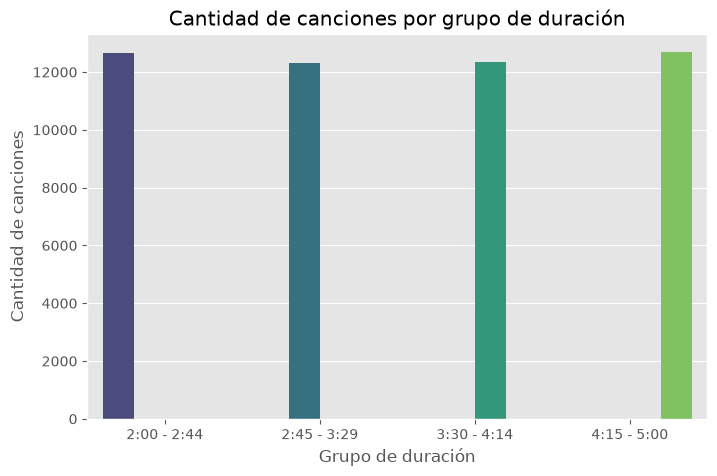

In [52]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Grupo_Duracion", hue="Grupo_Duracion", legend=False,
              order=["2:00 - 2:44", "2:45 - 3:29", "3:30 - 4:14", "4:15 - 5:00"], palette="viridis")
plt.title("Cantidad de canciones por grupo de duración")
plt.xlabel("Grupo de duración")
plt.ylabel("Cantidad de canciones")
plt.show()

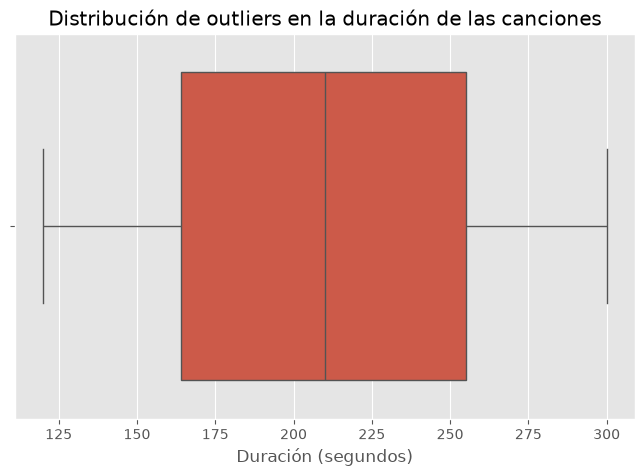

In [53]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Duration"])
plt.title("Distribución de outliers en la duración de las canciones")
plt.xlabel("Duración (segundos)")
plt.show()

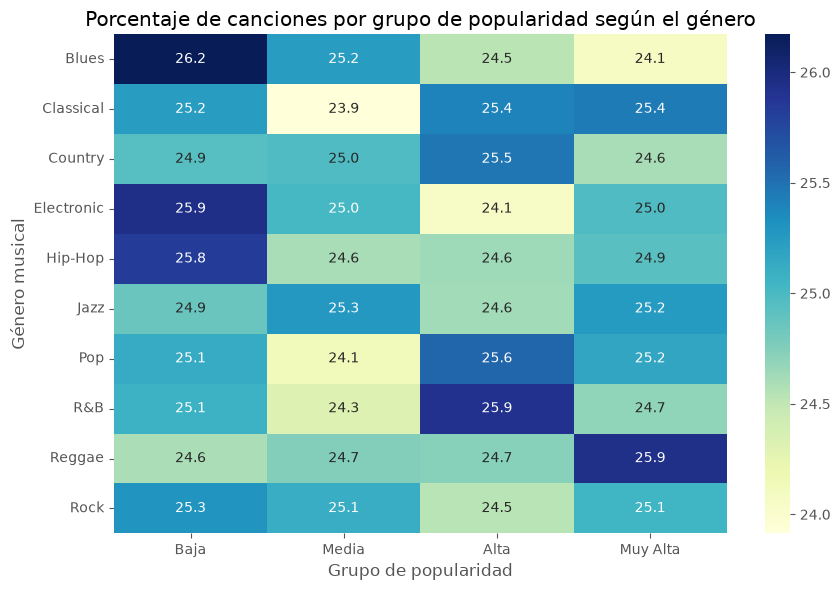

In [54]:
tabla = pd.crosstab(df["Genre"], df["Grupo_Popularidad"], normalize="index") * 100
tabla = tabla[["Baja", "Media", "Alta", "Muy Alta"]]

plt.figure(figsize=(9, 6))
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Porcentaje de canciones por grupo de popularidad según el género")
plt.xlabel("Grupo de popularidad")
plt.ylabel("Género musical")
plt.tight_layout()
plt.show()

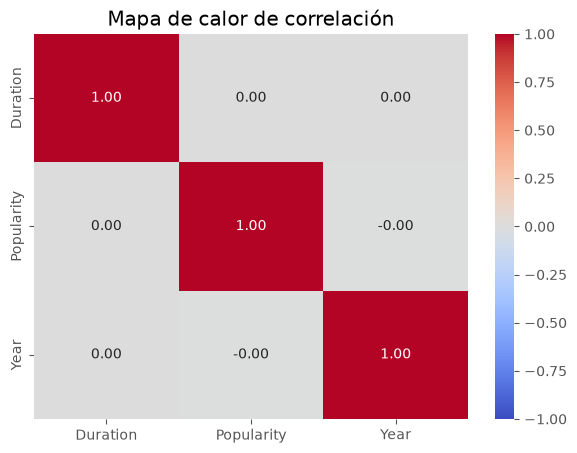

In [55]:
corr = df[["Duration", "Popularity", "Year"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Mapa de calor de correlación")
plt.show()